In [19]:
# Install the libraries required for analysis and regression
%pip install pandas numpy matplotlib seaborn scikit-learn xgboost joblib

In [18]:
from google.colab import files

uploaded = files.upload()

Saving sample_submission.csv to sample_submission (1).csv
Saving test.csv to test (1).csv
Saving train.csv to train (1).csv


In [20]:
# Import data manipulation and visualization libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path

# Import preprocessing and model selection tools
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_val_score,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Import regression models
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)
from xgboost import XGBRegressor

# Load CSV files (files were uploaded directly to the current directory)
DATA_DIR = Path(".")

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")

# Display the dataset dimensions
print("Training data:", train.shape)
print("Test data:", test.shape)

# Display a sample of the training data
display(train.head())

Training data: (1460, 81)
Test data: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageQual,81
GarageFinish,81
GarageType,81


Duplicate rows: 0


,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


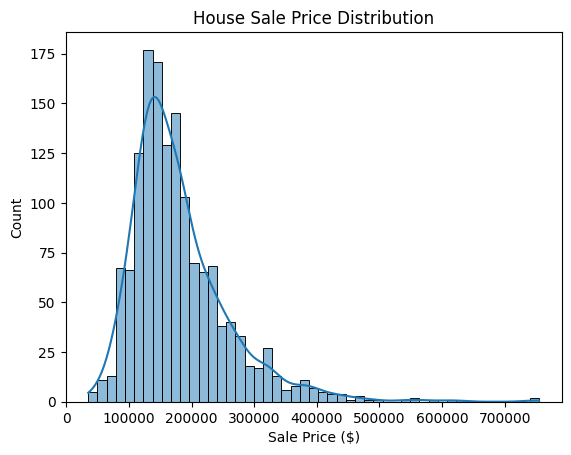

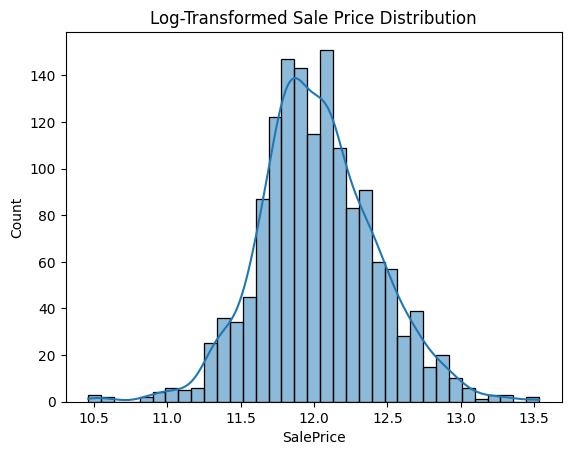

In [21]:
# Inspect the dataset structure and data types
train.info()

# Count missing values in each column
missing = train.isnull().sum().sort_values(ascending=False)
display(missing[missing > 0].head(20))

# Check duplicate rows
print("Duplicate rows:", train.duplicated().sum())

# Review the target distribution
display(train["SalePrice"].describe())

# Visualize the sale price distribution
sns.histplot(train["SalePrice"], kde=True)
plt.title("House Sale Price Distribution")
plt.xlabel("Sale Price ($)")
plt.show()

# Visualize the logarithm-transformed target
sns.histplot(np.log1p(train["SalePrice"]), kde=True)
plt.title("Log-Transformed Sale Price Distribution")
plt.show()

feature engineering

In [22]:
# Create copies so the original datasets remain unchanged
train_fe = train.copy()
test_fe = test.copy()

# Combine train and test features to apply consistent feature engineering
combined = pd.concat(
    [train_fe.drop(columns=["SalePrice"]), test_fe],
    axis=0,
    ignore_index=True
)

# Create additional area-related features
combined["TotalSF"] = (
    combined["TotalBsmtSF"].fillna(0)
    + combined["1stFlrSF"].fillna(0)
    + combined["2ndFlrSF"].fillna(0)
)

combined["TotalBathrooms"] = (
    combined["FullBath"].fillna(0)
    + 0.5 * combined["HalfBath"].fillna(0)
    + combined["BsmtFullBath"].fillna(0)
    + 0.5 * combined["BsmtHalfBath"].fillna(0)
)

# Estimate house age and years since remodeling
combined["HouseAge"] = combined["YrSold"] - combined["YearBuilt"]
combined["RemodelAge"] = combined["YrSold"] - combined["YearRemodAdd"]

# Split the engineered data back into training and test features
X = combined.iloc[:len(train)].copy()
X_test = combined.iloc[len(train):].copy()

# Use the logarithm of sale price as the training target
y = np.log1p(train["SalePrice"])

print("Training features:", X.shape)
print("Competition test features:", X_test.shape)

Training features: (1460, 84)
Competition test features: (1459, 84)


split and build processing

In [23]:
# Keep a validation set for an honest local performance estimate
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Impute missing numeric values and scale the features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Impute missing categorical values and encode categories
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate preprocessing to each feature type
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))

Training rows: 1168
Validation rows: 292


train model

In [24]:
# Define five regression models
models = {
    "Ridge Regression": Ridge(alpha=10.0),

    "Random Forest": RandomForestRegressor(
        n_estimators=400,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=400,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.04,
        max_depth=3,
        loss="huber",
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=1000,
        learning_rate=0.03,
        max_depth=3,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.01,
        reg_lambda=2,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
}

# Train and evaluate each model
trained_models = {}
results = []

for name, model in models.items():

    # Build a complete preprocessing and regression pipeline
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Fit the model using training data
    pipeline.fit(X_train, y_train)

    # Predict log prices for the validation set
    log_predictions = pipeline.predict(X_valid)

    # Convert predictions back to dollar prices
    predictions = np.maximum(np.expm1(log_predictions), 0)
    actual_prices = np.expm1(y_valid)

    # Calculate validation metrics
    rmse = np.sqrt(mean_squared_error(actual_prices, predictions))
    mae = mean_absolute_error(actual_prices, predictions)
    r2 = r2_score(actual_prices, predictions)

    # Calculate RMSLE on the log-price scale
    rmsle = np.sqrt(mean_squared_error(y_valid, log_predictions))

    results.append({
        "Model": name,
        "RMSE": rmse,
        "RMSLE": rmsle,
        "MAE": mae,
        "R2": r2
    })

    trained_models[name] = pipeline

# Compare the models by RMSLE
results_df = pd.DataFrame(results).sort_values(
    "RMSLE", ascending=True
).reset_index(drop=True)

display(results_df.round(4))

,Model,RMSE,RMSLE,MAE,R2
0,XGBoost,27120.4904,0.1311,15618.3837,0.9041
1,Gradient Boosting,29613.5913,0.1324,15947.2723,0.8857
2,Ridge Regression,25102.8738,0.1359,16436.4465,0.9178
3,Extra Trees,27028.0948,0.1476,16692.5403,0.9048
4,Random Forest,30998.0843,0.1483,17546.2033,0.8747


cross validation

In [25]:
# Use five-fold cross-validation on the training split
cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for name, model in models.items():

    # Keep preprocessing inside the pipeline to avoid data leakage
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Negative RMSE is returned by scikit-learn, so convert it to positive
    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=1
    )

    cv_results.append({
        "Model": name,
        "Mean CV RMSLE": -scores.mean(),
        "CV Standard Deviation": scores.std()
    })

cv_results_df = pd.DataFrame(cv_results).sort_values(
    "Mean CV RMSLE"
)

display(cv_results_df.round(4))

,Model,Mean CV RMSLE,CV Standard Deviation
4,XGBoost,0.1214,0.0133
3,Gradient Boosting,0.1261,0.0187
2,Extra Trees,0.1387,0.0133
0,Ridge Regression,0.1420,0.0285
1,Random Forest,0.1436,0.0157


tune xgbost

In [26]:
# Define the XGBoost pipeline
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

# Define a compact hyperparameter search space
param_grid = {
    "model__n_estimators": [500, 800, 1000],
    "model__max_depth": [2, 3, 4],
    "model__learning_rate": [0.02, 0.03, 0.05],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0]
}

# Search for the best parameters using cross-validation
search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best CV RMSLE:", -search.best_score_)

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best parameters: {'model__colsample_bytree': 0.8, 'model__learning_rate': 0.02, 'model__max_depth': 4, 'model__n_estimators': 1000, 'model__subsample': 0.8}
Best CV RMSLE: 0.12402264780842798


evulate model

Validation RMSE: 25272.858927834935
Validation RMSLE: 0.1302675991878477
Validation MAE: 15105.612197666966
Validation R2: 0.9167287829573969


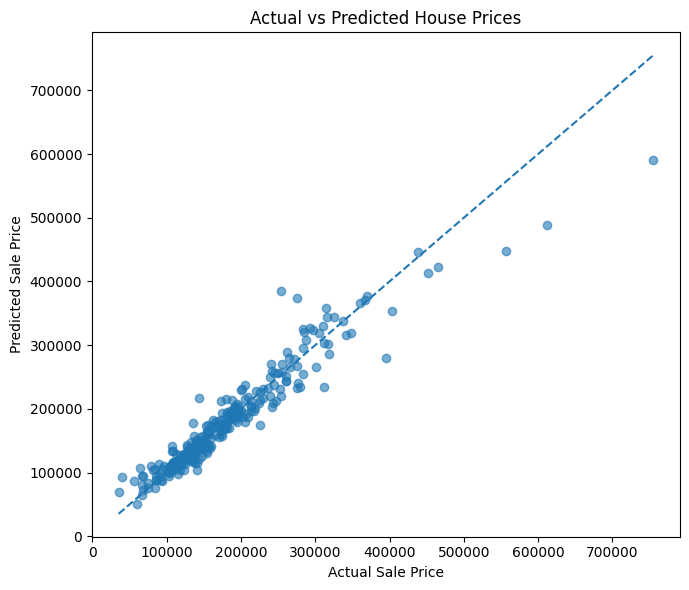

In [27]:
# Evaluate the tuned model on the held-out validation set
best_model = search.best_estimator_

valid_log_predictions = best_model.predict(X_valid)
valid_predictions = np.maximum(
    np.expm1(valid_log_predictions), 0
)
valid_actual = np.expm1(y_valid)

print("Validation RMSE:",
      np.sqrt(mean_squared_error(valid_actual, valid_predictions)))

print("Validation RMSLE:",
      np.sqrt(mean_squared_error(y_valid, valid_log_predictions)))

print("Validation MAE:",
      mean_absolute_error(valid_actual, valid_predictions))

print("Validation R2:",
      r2_score(valid_actual, valid_predictions))

# Plot actual prices against predicted prices
plt.figure(figsize=(7, 6))
plt.scatter(valid_actual, valid_predictions, alpha=0.6)
plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted House Prices")

# Add a reference line
lower = min(valid_actual.min(), valid_predictions.min())
upper = max(valid_actual.max(), valid_predictions.max())
plt.plot([lower, upper], [lower, upper], linestyle="--")

plt.tight_layout()
plt.show()

train final model

In [28]:
# Refit the selected model using all labeled training records
final_model = search.best_estimator_
final_model.fit(X, y)

# Predict prices for the Kaggle competition test data
test_log_predictions = final_model.predict(X_test)
test_predictions = np.maximum(
    np.expm1(test_log_predictions), 0
)

# Create the submission in the required format
submission = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": test_predictions
})

# Save the submission file
submission.to_csv("submission.csv", index=False)

# Inspect the submission before uploading
display(submission.head())
print("Submission shape:", submission.shape)
print("Missing predictions:", submission["SalePrice"].isnull().sum())
print("Saved submission.csv")

,Id,SalePrice
0,1461,125607.335938
1,1462,163670.265625
2,1463,184046.234375
3,1464,192229.875000
4,1465,187240.921875


Submission shape: (1459, 2)
Missing predictions: 0
Saved submission.csv


In [29]:
# Download the generated Kaggle submission file in Google Colab
from google.colab import files
files.download("submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>